In [1]:
import matplotlib.pyplot as plt
import gym
import gym_mppt
from gym import envs
env = gym.make("mppt_shaded-v3")

num_obs = env.observation_space.shape[0]
print("Size of Observation Space ->  {}".format(num_obs))
print(env.observation_space)

print()

num_actions = env.action_space.shape[0]
print("Size of Action Space ->  {}".format(num_actions))
print(env.action_space)

Size of Observation Space ->  8
Box([  0.   0.   0. -inf -inf -inf -inf -inf], [212.  inf  inf  inf  inf  inf  inf  inf], (8,), float32)

Size of Action Space ->  1
Box([-5.], [5.], (1,), float32)


C:\Users\archi\anaconda3\envs\BTPtorch\lib\site-packages\gym\spaces\box.py:73: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(


In [2]:
obs = env.reset()
obs = env.render([8, 10, 6, 10, 5, 10, 25, 1000])
# obs = env.render([2, 10, 8, 10, 7, 10, 25, 1000])
# obs = env.render([1, 10, 7, 10, 3, 10, 25, 1000])

obs, reward, done, info = env.step(1)
voltlst, currlst, powerlst, normlst = [0.0], [info['Current']], [0.0], [0.0]
voltlst.append(info['Voltage'])
currlst.append(info['Current'])
powerlst.append(info['Power'])
normlst.append(info['NormPower'])
print(info['Shading'], info['Temperature'], info['Irradiance'])

for i in range(2, 5000):
    deltaPower = powerlst[i-1] - powerlst[i-2]
    deltaVoltage = voltlst[i-1] - voltlst[i-2]
    
    if deltaPower > 0.0:
        if deltaVoltage > 0.0:
            delta = 1.0
        else:
            delta = -1.0
    else:
        if deltaVoltage > 0.0:
            delta = -1.0
        else:
            delta = 1.0
    
    obs, reward, done, info = env.step(delta)
    
    voltlst.append(info['Voltage'])
    currlst.append(info['Current'])
    powerlst.append(info['Power'])
    normlst.append(info['NormPower'])

[8, 10, 6, 10, 5, 10] 30.02 600


In [3]:
len(powerlst)

5000

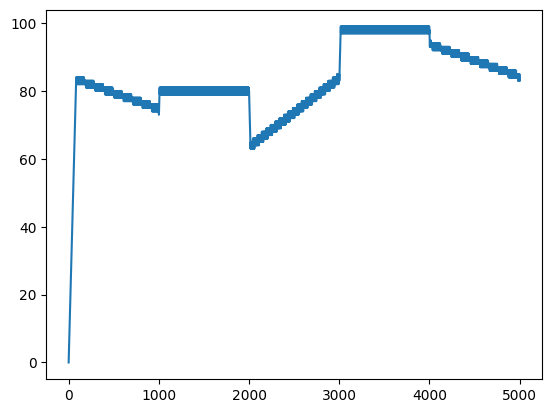

In [4]:
plt.plot(voltlst)

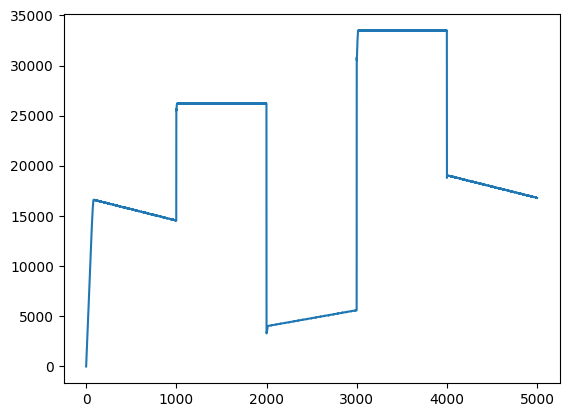

In [5]:
plt.plot(powerlst)

In [6]:
sum(normlst[200:1000])/len(normlst[200:1000])*100

50.21828501520598

In [7]:
import random
import time

rewlst = []
timelst = []

for x in range(100):
    start_time = time.time()
    
    obs = env.reset()
    a = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
    b = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
    c = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
    obs = env.render([a, 10, b, 10, c, 10, 25, 1000])

    obs, reward, done, info = env.step(1)
    voltlst, currlst, powerlst, normlst = [0.0], [info['Current']], [0.0], [0.0]
    voltlst.append(info['Voltage'])
    currlst.append(info['Current'])
    powerlst.append(info['Power'])
    normlst.append(info['NormPower'])
    print(info['Shading'], info['Temperature'], info['Irradiance'])

    for i in range(2, 1000):
        deltaPower = powerlst[i-1] - powerlst[i-2]
        deltaVoltage = voltlst[i-1] - voltlst[i-2]

        if deltaPower > 0.0:
            if deltaVoltage > 0.0:
                delta = 1.0
            else:
                delta = -1.0
        else:
            if deltaVoltage > 0.0:
                delta = -1.0
            else:
                delta = 1.0

        obs, reward, done, info = env.step(delta)

        voltlst.append(info['Voltage'])
        currlst.append(info['Current'])
        powerlst.append(info['Power'])
        normlst.append(info['NormPower'])
        
    rewlst.append(sum(normlst[200:1000]))
#     print(rewlst[-1])
    
    end_time = time.time()
    print(end_time - start_time)
    timelst.append(end_time - start_time)

[9, 10, 8, 10, 3, 10] 25 1000
0.19399547576904297
[10, 10, 1, 10, 9, 10] 25 1000
0.22600030899047852
[6, 10, 6, 10, 5, 10] 25 1000
0.17800283432006836
[10, 10, 4, 10, 10, 10] 25 1000
0.1869978904724121
[6, 10, 6, 10, 6, 10] 25 1000
0.18200039863586426
[6, 10, 9, 10, 10, 10] 25 1000
0.18500089645385742
[2, 10, 1, 10, 2, 10] 25 1000
0.24500203132629395
[1, 10, 10, 10, 5, 10] 25 1000
0.2149965763092041
[9, 10, 1, 10, 10, 10] 25 1000
0.21900105476379395
[1, 10, 2, 10, 5, 10] 25 1000
0.22700023651123047
[4, 10, 3, 10, 5, 10] 25 1000
0.19100069999694824
[10, 10, 10, 10, 7, 10] 25 1000
0.18199968338012695
[5, 10, 1, 10, 5, 10] 25 1000
0.2239992618560791
[1, 10, 8, 10, 9, 10] 25 1000
0.2109999656677246
[9, 10, 6, 10, 2, 10] 25 1000
0.19300198554992676
[9, 10, 9, 10, 1, 10] 25 1000
0.21700000762939453
[6, 10, 2, 10, 9, 10] 25 1000
0.18699860572814941
[1, 10, 6, 10, 1, 10] 25 1000
0.2500278949737549
[2, 10, 5, 10, 10, 10] 25 1000
0.19600367546081543
[4, 10, 9, 10, 3, 10] 25 1000
0.18799948692321

In [8]:
((sum(timelst) / 100) / 1000) * 1000

0.20194028854370116

In [8]:
((sum(rewlst)/8)/len(rewlst))

71.87715071062445

In [10]:
newrewlst = [i/8 for i in rewlst]

In [12]:
import statistics
statistics.stdev(newrewlst)

29.10537989083265

In [7]:
import numpy as np

In [8]:
gmpp = np.load('irrtempgmpp.npy', allow_pickle=True)

In [9]:
import random

powlst = np.zeros((100), dtype=object)
shading = np.zeros((100), dtype=object)

for x in range(100):
    obs = env.reset()
    a = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
    b = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
    c = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
    obs = env.render([a, 10, b, 10, c, 10, 25, 1000])

    obs, reward, done, info = env.step(1)
    voltlst, currlst, powerlst, normlst = [0.0], [info['Current']], [0.0], [0.0]
    voltlst.append(info['Voltage'])
    currlst.append(info['Current'])
    powerlst.append(info['Power'])
    normlst.append(info['NormPower'])
    print(info['Shading'], info['Temperature'], info['Irradiance'])

    for i in range(2, 5000):
        deltaPower = powerlst[i-1] - powerlst[i-2]
        deltaVoltage = voltlst[i-1] - voltlst[i-2]

        if deltaPower > 0.0:
            if deltaVoltage > 0.0:
                delta = 1.0
            else:
                delta = -1.0
        else:
            if deltaVoltage > 0.0:
                delta = -1.0
            else:
                delta = 1.0

        obs, reward, done, info = env.step(delta)

        voltlst.append(info['Voltage'])
        currlst.append(info['Current'])
        powerlst.append(info['Power'])
        normlst.append(info['NormPower'])
    
    powlst[x] = powerlst
    shading[x] = info['Shading']
#     rewlst.append(sum(normlst[200:1000]))
#     print(rewlst[-1])

[1, 10, 10, 10, 4, 10] 30.02 600
[7, 10, 8, 10, 4, 10] 30.02 600
[3, 10, 9, 10, 4, 10] 30.02 600
[2, 10, 9, 10, 3, 10] 30.02 600
[3, 10, 6, 10, 8, 10] 30.02 600
[6, 10, 1, 10, 10, 10] 30.02 600
[9, 10, 1, 10, 8, 10] 30.02 600
[1, 10, 3, 10, 2, 10] 30.02 600
[7, 10, 3, 10, 7, 10] 30.02 600
[6, 10, 6, 10, 4, 10] 30.02 600
[6, 10, 10, 10, 3, 10] 30.02 600
[9, 10, 9, 10, 3, 10] 30.02 600
[4, 10, 3, 10, 5, 10] 30.02 600
[5, 10, 6, 10, 8, 10] 30.02 600
[7, 10, 10, 10, 6, 10] 30.02 600
[10, 10, 4, 10, 6, 10] 30.02 600
[5, 10, 6, 10, 4, 10] 30.02 600
[9, 10, 9, 10, 3, 10] 30.02 600
[10, 10, 2, 10, 5, 10] 30.02 600
[3, 10, 2, 10, 7, 10] 30.02 600
[8, 10, 1, 10, 7, 10] 30.02 600
[1, 10, 2, 10, 9, 10] 30.02 600
[3, 10, 2, 10, 6, 10] 30.02 600
[7, 10, 7, 10, 10, 10] 30.02 600
[1, 10, 10, 10, 6, 10] 30.02 600
[10, 10, 9, 10, 7, 10] 30.02 600
[7, 10, 9, 10, 6, 10] 30.02 600
[5, 10, 10, 10, 2, 10] 30.02 600
[6, 10, 8, 10, 2, 10] 30.02 600
[6, 10, 5, 10, 9, 10] 30.02 600
[2, 10, 6, 10, 8, 10] 30.02 60

In [10]:
errormean = []

for i in range(100):
    lst = powlst[i]
      
    errori = sum([100-((i-j)/i*100) if i != 0 else None for i,j in zip(gmpp[shading[i][0]][shading[i][2]][shading[i][4]][200:5000],lst[200:5000])])/4800
    
    print(shading[i], errori, sep = ', ', end = '\n')
    errormean.append(errori)

[1, 10, 10, 10, 4, 10], 56.5984508160959
[7, 10, 8, 10, 4, 10], 93.59415861554567
[3, 10, 9, 10, 4, 10], 82.821243745792
[2, 10, 9, 10, 3, 10], 59.413053275905135
[3, 10, 6, 10, 8, 10], 93.94948610592695
[6, 10, 1, 10, 10, 10], 72.22848948262117
[9, 10, 1, 10, 8, 10], 69.66240616123446
[1, 10, 3, 10, 2, 10], 91.11335974926428
[7, 10, 3, 10, 7, 10], 90.46157148627104
[6, 10, 6, 10, 4, 10], 99.49821205398082
[6, 10, 10, 10, 3, 10], 88.6812189151669
[9, 10, 9, 10, 3, 10], 81.82028592806955
[4, 10, 3, 10, 5, 10], 96.23796485548583
[5, 10, 6, 10, 8, 10], 99.88589439120793
[7, 10, 10, 10, 6, 10], 99.90948663329026
[10, 10, 4, 10, 6, 10], 99.46893260606724
[5, 10, 6, 10, 4, 10], 99.92217789450505
[9, 10, 9, 10, 3, 10], 81.82028592806955
[10, 10, 2, 10, 5, 10], 77.3414444223708
[3, 10, 2, 10, 7, 10], 96.02571991998298
[8, 10, 1, 10, 7, 10], 70.6761078520097
[1, 10, 2, 10, 9, 10], 52.854467008800285
[3, 10, 2, 10, 6, 10], 95.99004162095036
[7, 10, 7, 10, 10, 10], 99.83862506593859
[1, 10, 10, 1

In [11]:
sum(errormean)/len(errormean)

87.44712094810635

In [13]:
import statistics
statistics.stdev(errormean)

14.393752326951107